In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec


# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


from msolver import IASGKS, MMGKS, VanillaGKS

# Setup toy problem

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

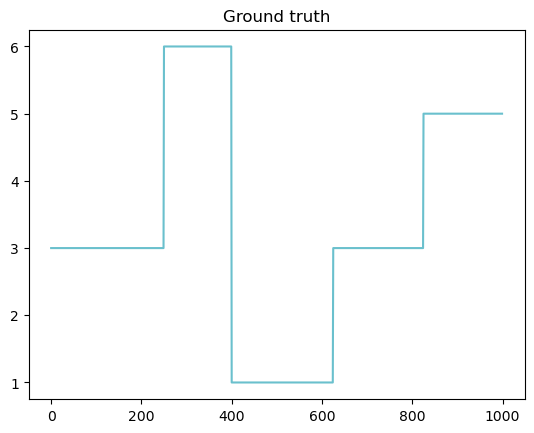

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

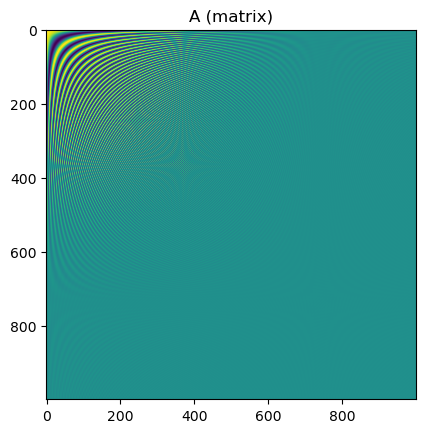

In [6]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [7]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

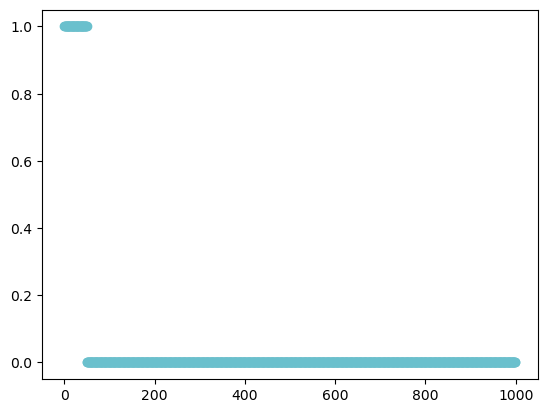

In [8]:
plt.scatter(grid, mask)
plt.show()

In [9]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

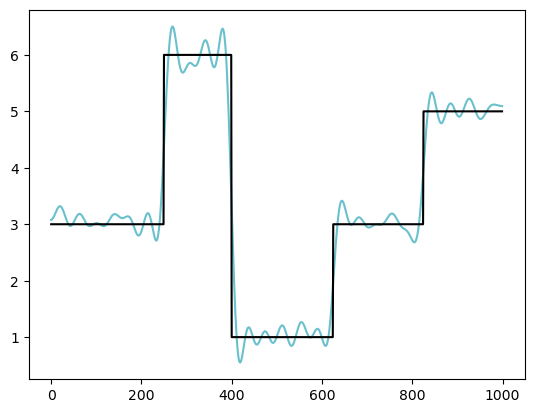

In [10]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [11]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)

#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-4
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# Run all methods

In [12]:
n_its = 200
method = "dp"

# mmpdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
#                                                  regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params, 
#                                                  regparam_kwargs={"eta":1.01})

#print("Finished S-GKS (priorconditioned) (initial MMGKS solve)")

vpdata = gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=None, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished L2 GKS (priorconditioned)")

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=None, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)
print("Finished L2 GKS (vanilla)")

x0 = vdata["x"]
lambda0 = vdata["lambdah"]

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")

data = iasgks_solver.solve(n_iter=n_its, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

resdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=30)
print("Finished S-GKS (restarted)")


recdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=x0, lambdah0=lambda0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=15, max_dim=30, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine/../../msolver.py:713: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
31.623190955402396
116.24592604025504
131.97582757028684
139.3080112870831
141.62733364738887
143.01885429086025
143.37881256381542
143.4830559244385
143.50764281882775
143.51449535809357
143.51610550832734
143.51638017005763
143.51645771067905
143.51647445330929
143.5164766047553
143.51647693212195
143.51647700829818
143.51647701620382
143.51647701729692
143.51647701743514
143.5164770174443
143.51647701744477
143.51647701744477
143.516477017445
143.51647701744494
143.51647701744486
143.5164770174448
143.51647701744486
143.51647701744488
143.51647701744483
143.51647701744483
143.5164770174449
143.51647701744497
143.5164770174448
143.5164770174448
143.51647701744497
143.51647701744494
143.51647701744508
143.51647701744506
143.51647701744469
143.5164770174451
143.51647701744514
143.51647701744508
143.51647701744508
143.51647701744508
143.51647701744508
143.5164770174451
143.51647701744506
143.51647701744508
143.51647701744503
143.51647701744508
143.516477017

712.4352939343164
313.37688956665164
173.65850933017586
160.22316437180504
156.42683371661784
154.5182676308331
153.02692623933018
151.53095534516513
149.85582845753214
148.28508304070328
147.03265125815278
146.16390266639357
145.5579899324737
145.11634310699793
144.7776471164702
144.49582192950552
144.2765757634909
144.09680125755997
143.95377910532878
143.83566235329278
143.7421485449182
143.67958142370674
143.63150284563577
143.59602087803415
143.57101709999938
143.55184798233
143.53864453656294
143.52944053731824
143.5226257228036
143.51812172305557
143.5151546915997
143.51349734228555
143.51286739220728
143.51275201379985
143.51298594693645
143.51342217547386
143.51391147873576
143.51437853738582
143.51482640259647
143.51525087768073
143.51557453481388
143.51585608698917
143.51607582590736
143.51622167901527
143.5163353229858
143.51643068333658
143.51649608465053
143.51653867376675
143.51656341196082
143.51657662998304
143.5165808589555
143.51657785191722
143.51656911946577
143.51

1e-07
33.175157806475106
44.12686919815751
74.50211455124648
103.28016197373576
120.56827126288248
135.55892502726456
144.95930103651406
154.7715905772789
167.2987743532809
174.53131803400873
185.80080756161055
193.17572208120038
207.76090120658165
222.43290162569446
239.56989648666774
251.2980022547798
276.24289861636566
293.57739322582034
301.5491255521499
304.47625121926575
307.3369360692009
313.1143817420943
316.6843308966126
319.7338190452837
323.63425654790024
327.91073668910644
333.55794111265146
340.84747579696057
351.33275390643325
368.8457083353124
403.0904150746674
484.52814007365475
703.8481595792155
1262.840724554961
3996.362505033765
28063.75541429727
292519.2355090874
3705286.359988242
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
1000

58.00580288168887
87.6132538462664
107.4643048364895
125.66018799619634
142.49245751566608
156.92848118056978
168.40969310062937
176.7625096551067
181.8174512110553
183.75426495103176
183.08126194177956
180.23689375940725
175.75742510087454
170.0321637413218
163.5404343645856
156.7940749754463
150.06843042426172
143.5985925930499
137.62853185901997
132.30017977251748
127.67755534335062
123.79256546164102
120.70330171539
118.43811951113747
116.97848394268728
116.40717698059981
116.61007389444333
117.6236664403455
118.75975101816246
119.70917040727235
120.38637381756236
120.86795279579044
121.23946135726011
121.58681070258451
121.93239605150596
122.44165886014557
123.83264637428572
126.84645906616879
130.8185480650015
134.3420493321013
136.32568456680815
136.74043832627228
136.82180068912427
137.12602252239049
137.9410492820373
139.64542106177208
142.7712870250763
147.4431370498896
154.07479942237293
161.5236073162528
169.0130838887707
175.82508644591113
181.61111301045358
186.4781109397

58.00580288168887
87.6132538462664
107.4643048364895
125.66018799619634
142.49245751566608
156.92848118056978
168.40969310062937
176.7625096551067
181.8174512110553
183.75426495103176
183.08126194177956
180.23689375940725
175.75742510087454
170.0321637413218
163.5404343645856
156.7940749754463
150.06843042426172
143.5985925930499
137.62853185901997
132.30017977251748
127.67755534335062
123.79256546164102
120.70330171539
118.43811951113747
116.73623383905444
146.96510560014826
181.82456684915616
167.38167626952017
93.52380816093698
106.99824592785696
138.71342421217975
144.8196136404811
115.45510253373278
104.89594211435518
128.52960124658776
142.9451380832785
128.3494726371516
112.80573806173336
120.31175956880969
132.20017697285562
132.47579077771397
122.43037885527183
118.97843799733872
128.9238706131735
137.99799362812195
132.3626372911366
126.20607915518843
130.7512036990307
138.6746145183903
140.43040014218732
137.5777499649713
138.76505817776442
143.7059502415187
146.258761096251

58.00580288168887
87.6132538462664
107.4643048364895
125.66018799619634
142.49245751566608
156.92848118056978
168.40969310062937
176.7625096551067
181.8174512110553
183.75426495103176
183.08126194177956
180.23689375940725
175.75742510087454
170.0321637413218
163.5404343645856
156.7940749754463
150.06843042426172
143.5985925930499
137.62853185901997
132.30017977251748
127.67755534335062
123.79256546164102
120.70330171539
118.43811951113747
(30, 30)
(30, 30)
(60, 30)
117.51596090723544
155.95764839619574
173.4874673003344
118.83825445821614
96.1744505277961
127.01027638800502
141.18190516632956
126.40446385842213
109.26622885261831
127.74595092007306
144.03427626412724
137.22860439292268
119.49992310069021
115.25803085124683
124.80238376466939
(30, 30)
(30, 30)
(60, 30)
128.37832365447795
140.95087729276867
148.33625294188846
154.4320036464379
156.62456636351914
147.95010345401442
142.09432277402007
157.34145453696465
179.90818857132035
170.88408307824707
125.5645467183532
144.0363186579

# Make plots

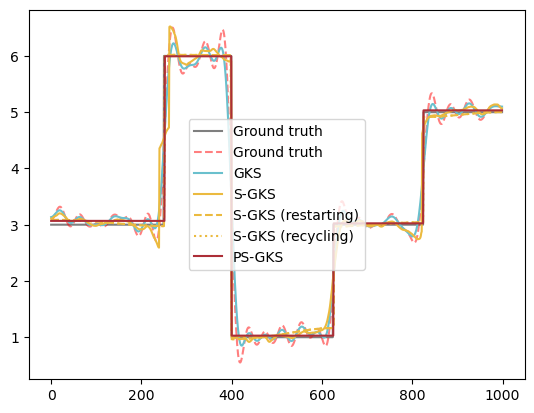

In [13]:
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.5)
plt.plot(A.T @ b, label="Ground truth", color="red", alpha=0.5, ls="--")
plt.plot(vdata["x"], label="GKS", color="C0")
plt.plot(data["x"], label="S-GKS", color="C1")
plt.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["x"], label="PS-GKS", color="C2")
plt.legend()
plt.show()

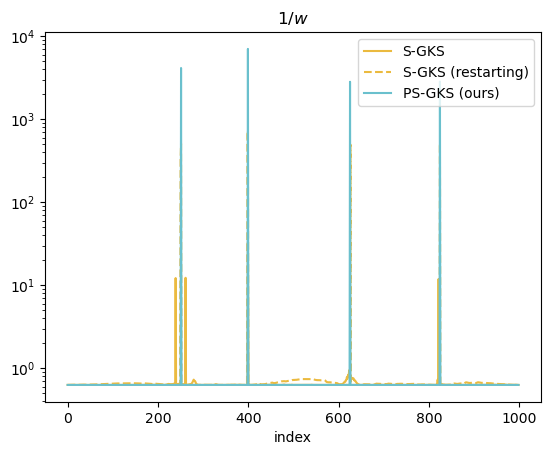

In [14]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(1.0/data['w'], label="S-GKS", color="C1")
plt.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
#plt.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(1.0/pdata['w'], label="PS-GKS (ours)")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

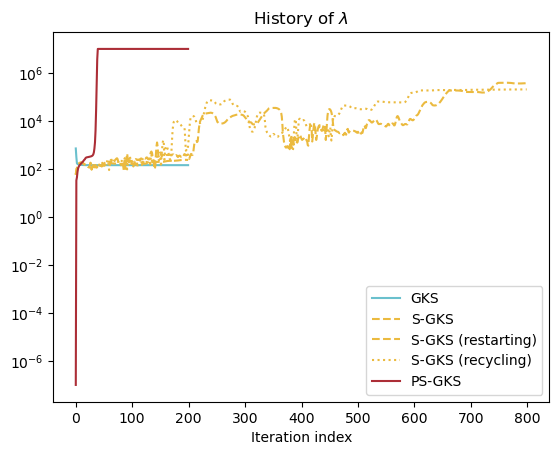

In [15]:
plt.semilogy(vdata["lambda_history"], label="GKS", color="C0")
plt.semilogy(data["lambda_history"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

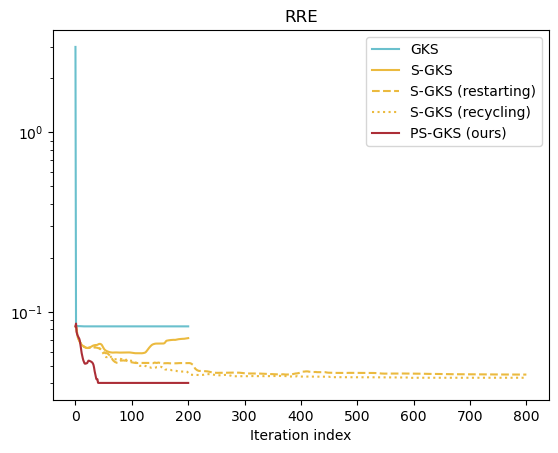

In [16]:
plt.semilogy(vdata["rre_history"], label="GKS", color="C0")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

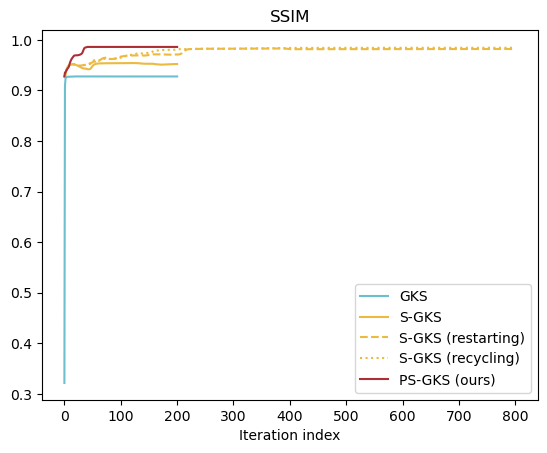

In [17]:
plt.plot(vdata["ssim_history"], label="GKS", color="C0")
plt.plot(data["ssim_history"], label="S-GKS", color="C1")
plt.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C2")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

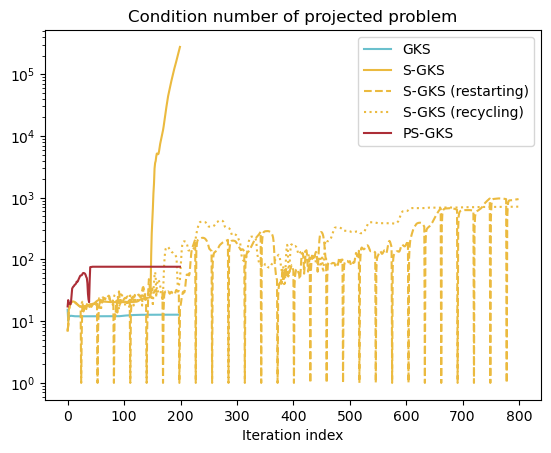

In [18]:
plt.semilogy(vdata["cond_ests"], label="GKS", color="C0")
plt.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
plt.title("Condition number of projected problem")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots in the paper

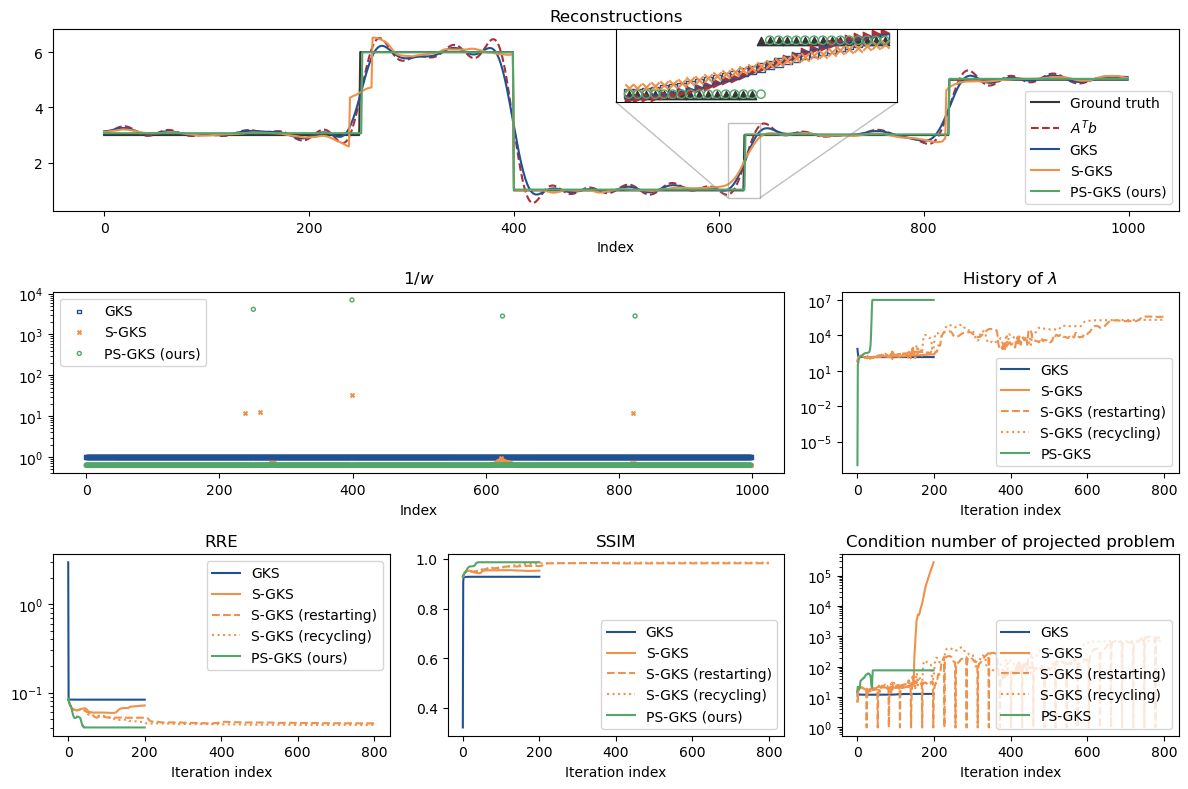

In [21]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(3, 3, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0, :])
ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
#ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
#ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS (ours)", color="C4")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
ax1.set_xlabel("Index")
ax1.set_title('Reconstructions')



ax2 = fig.add_subplot(gs[1, :2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
ax2.set_title("$1/w$")
ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend()


ax4 = fig.add_subplot(gs[1, 2])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend()



# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

ax3 = fig.add_subplot(gs[2, 0])
ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C4")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax3.set_title("RRE")
ax3.set_xlabel("Iteration index")
ax3.legend()



ax6 = fig.add_subplot(gs[2, 1])
ax6.plot(vdata["ssim_history"], label="GKS", color="C3")
ax6.plot(data["ssim_history"], label="S-GKS", color="C5")
ax6.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C4")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax6.set_title("SSIM")
ax6.set_xlabel("Iteration index")
ax6.legend()


ax5 = fig.add_subplot(gs[2, 2])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.legend(loc="lower right")


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_ias.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_ias.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


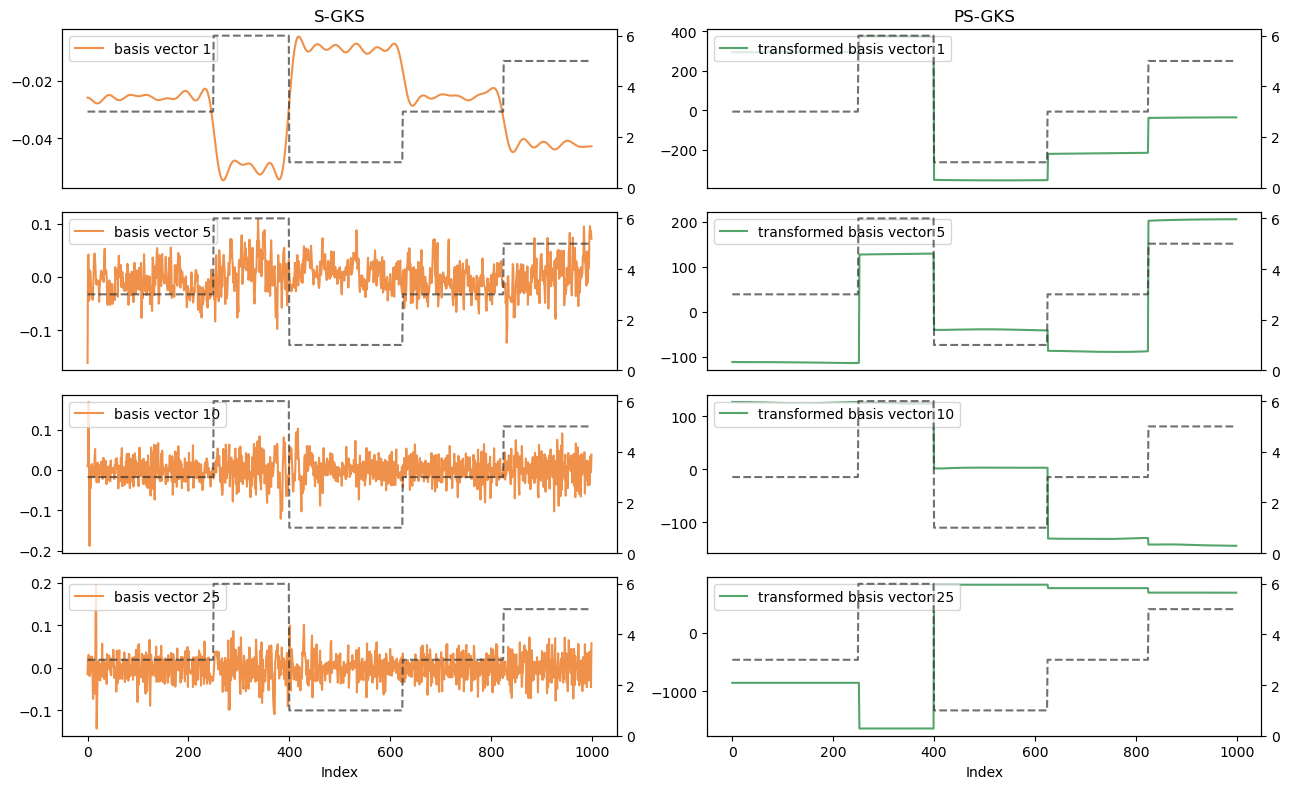

In [22]:
fig, axs = plt.subplots(4,2, figsize=(13,8))

loc = "upper left"

kk = 0
axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[0,0].legend(loc=loc)
axs[0,0].set_xticks([])
axs[0,0].set_title("S-GKS")
axst = axs[0,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[1,0].legend(loc=loc)
axs[1,0].set_xticks([])
axst = axs[1,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[2,0].legend(loc=loc)
axs[2,0].set_xticks([])
axst = axs[2,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[3,0].legend(loc=loc)
axs[3,0].set_xlabel("Index")
axst = axs[3,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])




kk = 0
axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[0,1].legend(loc=loc)
axs[0,1].set_xticks([])
axs[0,1].set_title("PS-GKS")
axst = axs[0,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[1,1].legend(loc=loc)
axs[1,1].set_xticks([])
axst = axs[1,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[2,1].legend(loc=loc)
axs[2,1].set_xticks([])
axst = axs[2,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[3,1].legend(loc=loc)
axs[3,1].set_xlabel("Index")
axst = axs[3,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

fig.tight_layout()
fig.savefig("1d_cosine_example_basis_vectors_ias.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors_ias.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()